# Лабораторная работа №2. Регрессионные модели на данных Boston Housing
**Цель:** построить и сравнить несколько регрессионных моделей для прогноза медианной стоимости жилья `medv`: классическую линейную (МНК), модель с парными взаимодействиями, а также регуляризованные Ridge и Lasso. Сравнение проводится по качеству на отложенной выборке, интерпретируемости коэффициентов и выполнению предпосылок МНК.

## 0. Подготовка окружения

> **Запрос к ассистенту:** «Нужен блок импортов для Colab под задачу регрессии: работа с таблицами и массивами (pandas, numpy), визуализация (matplotlib, seaborn), статистика из scipy, из sklearn — train_test_split, StandardScaler, модели LinearRegression/Ridge/Lasso/LassoCV, GridSearchCV и метрики качества; из statsmodels — OLS, расчёт VIF, тесты Бреуша–Пагана и Дарбина–Уотсона.»

Библиотеки распределены по ролям. `statsmodels` использую там, где нужна статистическая инференция: стандартные ошибки, t-статистики, p-значения, F-тест вложенных моделей. `scikit-learn` удобнее для прогнозных задач — в нём есть Ridge/Lasso и готовая кросс-валидация для подбора гиперпараметра. Одной библиотекой обе задачи закрыть неудобно.

In [ ]:
import time
import numpy as np                      # линейная алгебра, векторные операции
import pandas as pd                     # табличные данные
import matplotlib.pyplot as plt         # базовая визуализация
import seaborn as sns                   # heatmap для корреляционной матрицы
from scipy import stats                 # тест Шапиро–Уилка, Q-Q, асимметрия/эксцесс

from sklearn.model_selection import train_test_split, GridSearchCV   # hold-out и перебор гиперпараметров по сетке
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV  # линейные модели (с L2/L1-штрафом и без)
from sklearn.preprocessing import StandardScaler                     # z-преобразование признаков
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error  # метрики качества прогноза

import statsmodels.api as sm                                        # МНК с полной статистической сводкой
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF_j = 1 / (1 - R²_j)
from statsmodels.stats.diagnostic import het_breuschpagan           # H0: дисперсия остатков постоянна
from statsmodels.stats.stattools import durbin_watson               # статистика DW для автокорреляции 1-го порядка

plt.rcParams.update({'figure.dpi': 110})   # разрешение рисунков
SEED = 42                                  # фиксируем генератор случайных чисел для воспроизводимости
print("Готово")

Готово


## 1. Данные: загрузка, hold-out разбиение и масштабирование

> **Запрос к ассистенту:** «Считай CSV с Boston Housing по URL, выдели целевую переменную medv, раздели выборку в пропорции 70 на 30 с random_state=42 и приведи предикторы к z-оценкам; параметры StandardScaler оценивай только по train.»

Что здесь важно с методической точки зрения:
- **Отложенная выборка.** Качество модели, измеренное на тех же данных, на которых она обучалась, завышено (смещённая оценка). Поэтому 30% наблюдений откладываю и использую только для финальной оценки.
- **Стандартизация** $z = (x - \bar{x}) / s$. Признаки в исходных шкалах несопоставимы (доля, рубли налога, число комнат), а после преобразования коэффициент показывает эффект изменения признака на одно стандартное отклонение — их уже можно сравнивать по модулю. Для Ridge/Lasso это вообще обязательно: штраф $\lambda\sum\beta_j^2$ или $\lambda\sum|\beta_j|$ зависит от масштаба признака.
- **Без утечки.** Среднее и стандартное отклонение считаю только по обучающей части и этими же параметрами преобразую тест, иначе статистики тестовой выборки неявно попадут в обучение.

In [ ]:
URL = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(URL)             # исходный датасет: 506 строк, 14 столбцов
df['chas'] = df['chas'].astype(int)   # chas — фиктивная переменная (участок у реки), приводим к int

target = 'medv'                                   # отклик: медианная цена дома, тыс. $
features = [c for c in df.columns if c != target] # регрессоры — все прочие столбцы
X, y = df[features], df[target]

# hold-out 70/30; фиксированный random_state даёт одно и то же разбиение при каждом запуске
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, random_state=SEED)

# fit только на train -> transform для обеих частей (исключаем утечку информации из теста)
scaler = StandardScaler().fit(X_tr)
Xs_tr = pd.DataFrame(scaler.transform(X_tr), columns=features, index=X_tr.index)
Xs_te = pd.DataFrame(scaler.transform(X_te), columns=features, index=X_te.index)

print("Всего:", len(df), "| обучение:", len(X_tr), "| тест:", len(X_te), "| предикторов:", len(features))
df.head()

Всего: 506 | обучение: 354 | тест: 152 | предикторов: 13


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Итог разбиения: из 506 наблюдений 354 ушли в обучающую выборку и 152 — в тестовую. Регрессоров 13, отклик один (`medv`), пропущенных значений в данных нет, поэтому импутация не требуется.

In [ ]:
# Общие функции оценки качества — одинаково применяются ко всем моделям

def adj_r2(r2, n, p):
    # R²_adj = 1 - (1 - R²)(n - 1)/(n - p - 1): учитывает число регрессоров p при объёме выборки n
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def metrics(y_true, y_pred, p):
    r2 = r2_score(y_true, y_pred)
    return {'R2': r2,                                           # 1 - SS_res/SS_tot
            'adjR2': adj_r2(r2, len(y_true), p),                # поправка на сложность модели
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),# корень из MSE, чувствителен к большим ошибкам
            'MAE': mean_absolute_error(y_true, y_pred)}         # средний модуль ошибки, устойчивее к выбросам

---
## 2. Множественная линейная регрессия (МНК)

> **Запрос к ассистенту:** «Оцени МНК-модель через statsmodels по стандартизованным признакам. Нужны: сводка коэффициентов (оценка, SE, t, p), коэффициенты VIF, проверка остатков тестами Шапиро–Уилка, Бреуша–Пагана и Дарбина–Уотсона, а также диагностические графики остатков.»

Модель: $\hat{y} = \beta_0 + \sum_{j=1}^{13}\beta_j x_j$. Оценки МНК находятся из условия минимума суммы квадратов остатков $\sum (y_i - \hat{y}_i)^2$, в матричном виде $\hat\beta = (X^TX)^{-1}X^Ty$. Поскольку признаки центрированы, $\beta_0$ совпадает со средней ценой по обучающей выборке.

In [ ]:
# add_constant добавляет столбец единиц под свободный член β0
ols = sm.OLS(y_tr, sm.add_constant(Xs_tr)).fit()      # оценка параметров по train

pred_ols = ols.predict(sm.add_constant(Xs_te, has_constant='add'))   # has_constant='add' — принудительно добавить константу и в test
m_ols = metrics(y_te, pred_ols, len(features))

print(f"Обучающая: R² = {ols.rsquared:.3f}, скорр. R² = {ols.rsquared_adj:.3f}, F = {ols.fvalue:.1f} (p = {ols.f_pvalue:.1e})")
print(f"Тестовая:  R² = {m_ols['R2']:.3f}, скорр. R² = {m_ols['adjR2']:.3f}, RMSE = {m_ols['RMSE']:.2f}, MAE = {m_ols['MAE']:.2f}")
print(f"AIC = {ols.aic:.1f}, BIC = {ols.bic:.1f}")

Обучающая: R² = 0.743, скорр. R² = 0.734, F = 75.8 (p = 5.0e-92)
Тестовая:  R² = 0.711, скорр. R² = 0.684, RMSE = 4.64, MAE = 3.16
AIC = 2135.5, BIC = 2189.7


**Интерпретация.** На обучении $R^2 = 0{,}743$, на тесте $0{,}711$: модель объясняет около 71% вариации цены на новых для неё данных. Падение качества на тесте небольшое (≈0,03), значит признаков переобучения нет. F-статистика с $p \approx 5\cdot10^{-92}$ — модель в целом значима (гипотеза о равенстве нулю всех $\beta_j$ отвергается). RMSE = 4,64 тыс. $ — характерный размер ошибки прогноза, MAE = 3,16 тыс. $; то, что RMSE заметно больше MAE, указывает на наличие отдельных крупных промахов.

In [ ]:
# Сводка по коэффициентам: величина эффекта и его статистическая значимость
coef_tab = pd.DataFrame({
    'коэфф.': ols.params,        # β_j: изменение medv (тыс. $) при росте x_j на 1σ при прочих равных
    'ст.ошибка': ols.bse,        # SE(β_j) — стандартная ошибка оценки
    't': ols.tvalues,            # t = β_j / SE(β_j)
    'p': ols.pvalues             # p-value для H0: β_j = 0
})
coef_tab['значим (p<0.05)'] = np.where(coef_tab['p'] < 0.05, 'да', 'нет')
coef_tab.round(4)

,коэфф.,ст.ошибка,t,p,значим (p<0.05)
const,23.0158,0.2575,89.3791,0.0000,да
crim,-1.1083,0.3389,-3.2709,0.0012,да
zn,0.8084,0.3985,2.0289,0.0433,да
indus,0.3431,0.5044,0.6803,0.4968,нет
chas,0.8139,0.2704,3.0098,0.0028,да
nox,-1.7980,0.5539,-3.2460,0.0013,да
rm,2.9139,0.3562,8.1811,0.0000,да
age,-0.2989,0.4457,-0.6707,0.5029,нет
dis,-2.9425,0.5131,-5.7343,0.0000,да
rad,2.0942,0.7068,2.9627,0.0033,да


**Интерпретация.** На уровне $\alpha = 0{,}05$ гипотезу $H_0: \beta_j = 0$ не удаётся отвергнуть для `indus` (p = 0,50), `age` (p = 0,50) и `tax` (p = 0,060 — пограничный случай). Наибольший по модулю эффект у `lstat` (−3,89): рост доли населения с низким статусом на одно стандартное отклонение снижает цену почти на 3,9 тыс. $. Далее идут `dis` (−2,94) и `rm` (+2,91). Отрицательный знак означает обратную связь признака с ценой при фиксированных остальных регрессорах.

In [ ]:
# Мультиколлинеарность: VIF_j показывает, во сколько раз дисперсия β_j больше, чем при ортогональных регрессорах
Xc = sm.add_constant(Xs_tr)
vif = pd.Series({f: variance_inflation_factor(Xc.values, i)
                 for i, f in enumerate(Xc.columns) if f != 'const'}).sort_values(ascending=False)
vif.round(2)

,0
tax,8.88
rad,7.53
nox,4.63
dis,3.97
indus,3.84
age,3.00
lstat,2.68
zn,2.39
rm,1.91
ptratio,1.82


**Интерпретация.** Использую стандартную шкалу: VIF до 5 — норма, 5–10 — умеренная мультиколлинеарность, от 10 — сильная. Максимум у `tax` (8,88) и `rad` (7,53); это объясняется их высокой взаимной корреляцией (r ≈ 0,91) — индекс доступности магистралей и ставка налога фактически дублируют друг друга. Значений выше 10 нет, поэтому оценки МНК остаются устойчивыми, хотя стандартные ошибки у этих двух коэффициентов завышены (что и видно по SE ≈ 0,71–0,77 в таблице выше).

Шапиро–Уилк: W = 0.907, p = 5.9e-14
Бреуш–Паган: LM = 50.6, p = 2.4e-06
Дарбин–Уотсон: 2.09
Асимметрия остатков = 1.38, эксцесс = 4.84


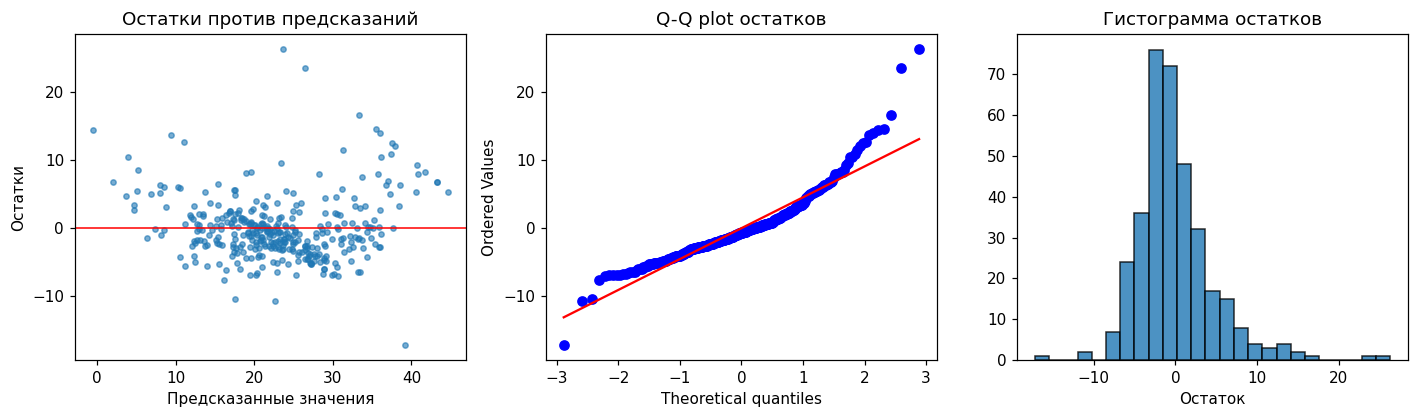

In [ ]:
# Анализ остатков e_i = y_i - ŷ_i: проверяем предпосылки Гаусса–Маркова и нормальность
res, fitted = ols.resid, ols.fittedvalues

sw = stats.shapiro(res)                 # H0: остатки распределены нормально
bp = het_breuschpagan(res, Xc)          # H0: гомоскедастичность (Var(e) не зависит от X)
dw = durbin_watson(res)                 # DW ≈ 2 при отсутствии автокорреляции, <2 — положительная, >2 — отрицательная
print(f"Шапиро–Уилк: W = {sw.statistic:.3f}, p = {sw.pvalue:.1e}")
print(f"Бреуш–Паган: LM = {bp[0]:.1f}, p = {bp[1]:.1e}")
print(f"Дарбин–Уотсон: {dw:.2f}")
print(f"Асимметрия остатков = {stats.skew(res):.2f}, эксцесс = {stats.kurtosis(res):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
ax[0].scatter(fitted, res, s=12, alpha=0.6); ax[0].axhline(0, color='red', lw=1)
ax[0].set_xlabel('Предсказанные значения'); ax[0].set_ylabel('Остатки'); ax[0].set_title('Остатки против предсказаний')
stats.probplot(res, dist='norm', plot=ax[1]); ax[1].set_title('Q-Q plot остатков')
ax[2].hist(res, bins=25, edgecolor='black', alpha=0.8); ax[2].set_title('Гистограмма остатков'); ax[2].set_xlabel('Остаток')
plt.tight_layout(); plt.show()

**Проверка предпосылок.**
- *Нормальность* отвергается: W = 0,907, $p \approx 6\cdot10^{-14}$. Распределение остатков скошено вправо (асимметрия 1,38) и островершинно (эксцесс 4,84); на Q-Q графике правый хвост уходит вверх от прямой — модель систематически недооценивает часть дорогих объектов.
- *Гомоскедастичность* отвергается тестом Бреуша–Пагана (LM = 50,6, $p \approx 2\cdot10^{-6}$). На графике «остатки–прогноз» разброс неоднороден, а облако имеет выраженную U-образную форму — это признак пропущенной нелинейности (например, по `lstat` или `rm`).
- *Автокорреляция* отсутствует: DW = 2,09 близко к 2.

Следствие: сами оценки МНК остаются несмещёнными, и для прогноза модель пригодна, но стандартные ошибки, а значит p-значения и доверительные интервалы, могут быть некорректны. Для строгой инференции стоило бы применить робастные (HC) ошибки или преобразовать отклик, например $\log(medv)$. Дополнительный вклад в отклонения вносит цензурирование цены на уровне 50 тыс. $ (отмечалось в ЛР №1).

---
## 3. Модель с эффектами взаимодействия

> **Запрос к ассистенту:** «Визуализируй корреляции признаков тепловой картой, по train выбери три пары предикторов с максимальным |r|, включи в регрессию их попарные произведения и сравни расширенную модель с исходной: F-тест для вложенных моделей, AIC/BIC и метрики на тестовой выборке.»

Аддитивная модель предполагает, что предельный эффект каждого признака постоянен. Если добавить слагаемое $\beta_{ab}\,x_a x_b$, то $\partial \hat y / \partial x_a = \beta_a + \beta_{ab}x_b$ — эффект $x_a$ начинает зависеть от уровня $x_b$. Пары выбираю по силе корреляции, как требует задание.

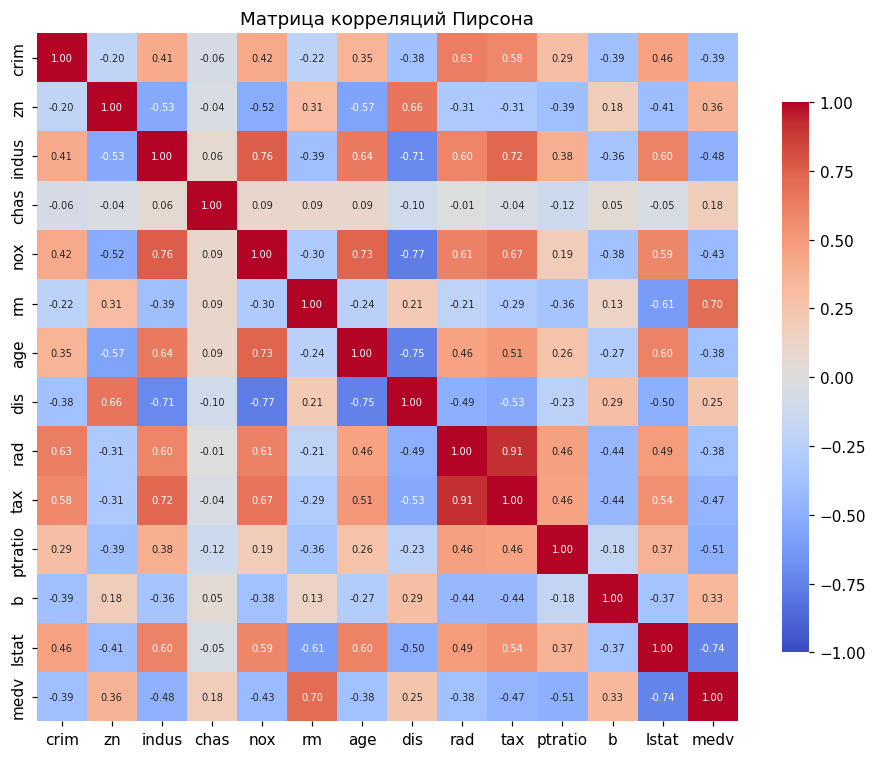

In [ ]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 6.5}, ax=ax, cbar_kws={'shrink': .8})
ax.set_title('Матрица корреляций Пирсона')
plt.tight_layout(); plt.show()

In [ ]:
# Ранжируем пары регрессоров по |r|; считаем только на train, чтобы тест не влиял на выбор
cf = X_tr.corr().abs()
pairs = cf.where(np.triu(np.ones(cf.shape), 1).astype(bool)).stack().sort_values(ascending=False)  # маска верхнего треугольника без диагонали — каждая пара один раз
signed = X_tr.corr()
top_pairs = [(a, b) for (a, b) in pairs.index[:3]]
for a, b in top_pairs:
    print(f"{a} и {b}: r = {signed.loc[a, b]:.3f}")

rad и tax: r = 0.909
nox и dis: r = -0.776
indus и nox: r = 0.764


По модулю коэффициента корреляции лидируют пары `rad`–`tax` (r = 0,909), `nox`–`dis` (r = −0,776) и `indus`–`nox` (r = 0,764). Они и формируют три новых регрессора-произведения.

In [ ]:
# Произведения считаются по z-оценкам: при центрированных признаках снижается корреляция x_a*x_b с самими x_a и x_b
def add_inter(Xs):
    Z = Xs.copy()
    for a, b in top_pairs:
        Z[f'{a}x{b}'] = Xs[a] * Xs[b]
    return Z

Zs_tr, Zs_te = add_inter(Xs_tr), add_inter(Xs_te)

ols_i = sm.OLS(y_tr, sm.add_constant(Zs_tr)).fit()
pred_i = ols_i.predict(sm.add_constant(Zs_te, has_constant='add'))
m_int = metrics(y_te, pred_i, Zs_tr.shape[1])

# F-тест вложенных моделей, H0: все три коэффициента при взаимодействиях равны нулю
F, pF, df_diff = ols_i.compare_f_test(ols)
print(f"F-тест: F = {F:.2f}, p = {pF:.3f}")
print(f"Тест: R² = {m_int['R2']:.3f}, скорр. R² = {m_int['adjR2']:.3f}, RMSE = {m_int['RMSE']:.2f}, MAE = {m_int['MAE']:.2f}")
print(f"AIC = {ols_i.aic:.1f} (было {ols.aic:.1f}), BIC = {ols_i.bic:.1f} (было {ols.bic:.1f})")

pd.DataFrame({'коэфф.': ols_i.params, 'ст.ошибка': ols_i.bse, 'p': ols_i.pvalues}).loc[[f'{a}x{b}' for a, b in top_pairs]].round(4)

F-тест: F = 2.20, p = 0.088
Тест: R² = 0.711, скорр. R² = 0.676, RMSE = 4.64, MAE = 3.21
AIC = 2134.6 (было 2135.5), BIC = 2200.4 (было 2189.7)


,коэфф.,ст.ошибка,p
radxtax,-0.3311,0.7286,0.6498
noxxdis,-1.8590,0.7435,0.0129
indusxnox,-0.4575,0.5720,0.4244


**Результаты для модели с взаимодействиями.**
- Индивидуально значимо только `nox×dis`: $\beta = -1{,}86$, p = 0,013. Предельный эффект загрязнения равен $\beta_{nox} + \beta_{nox\times dis}\cdot dis$, то есть в районах, удалённых от центров занятости (большой `dis`), негативное влияние `nox` на цену выражено сильнее. Взаимодействия `rad×tax` (p = 0,65) и `indus×nox` (p = 0,42) незначимы.
- Совместный F-тест: F = 2,20, p = 0,088. На 5%-м уровне гипотеза о нулевых коэффициентах при всех трёх произведениях не отвергается.
- AIC снизился едва заметно (2135,5 → 2134,6), а BIC, сильнее штрафующий за параметры, вырос (2189,7 → 2200,4). На тесте R² остался 0,711, скорректированный R² упал с 0,684 до 0,676, MAE немного вырос.
- Вывод: усложнение модели тремя слагаемыми не оправдано; прирост объяснённой дисперсии на train (0,743 → 0,748) не переносится на новые данные. Отрицательный результат здесь тоже информативен — линейная аддитивная спецификация для этих пар достаточна.

---
## 4. Регуляризация: Ridge и Lasso

> **Запрос к ассистенту:** «Подбери коэффициент регуляризации для Ridge перебором по сетке (GridSearchCV) и для Lasso с помощью LassoCV, в обоих случаях 5-fold CV. Нарисуй зависимость ошибки кросс-валидации от alpha и траектории коэффициентов Lasso. Отдельно построй Lasso с alpha, выбранным по правилу 1SE.»

Регуляризация добавляет к функционалу МНК штраф на величину коэффициентов:
- **Ridge:** $\min_\beta \|y - X\beta\|^2 + \alpha\|\beta\|_2^2$. Решение $\hat\beta = (X^TX + \alpha I)^{-1}X^Ty$ существует даже при плохо обусловленной $X^TX$; коэффициенты сжимаются к нулю, но не обнуляются. Особенно сильно сжимаются коэффициенты коррелированных признаков.
- **Lasso:** $\min_\beta \frac{1}{2n}\|y - X\beta\|^2 + \alpha\|\beta\|_1$. Из-за негладкости L1-нормы в нуле часть коэффициентов обращается точно в 0, т.е. метод одновременно выполняет отбор признаков.
- **Выбор $\alpha$** — 5-кратная кросс-валидация на обучающей выборке: каждый блок по очереди служит валидационным, ошибка усредняется. Тестовая выборка в подборе не участвует.
- **Правило одной стандартной ошибки:** среди всех $\alpha$, у которых CV-ошибка не превышает $\min \text{MSE} + SE$, выбирается наибольшее. Это даёт более разреженную модель без статистически различимой потери качества.

In [ ]:
# Ridge: логарифмическая сетка из 60 значений α на отрезке [1e-3, 1e3], критерий — MSE на 5 фолдах
alphas_r = np.logspace(-3, 3, 60)
t0 = time.perf_counter()
gs = GridSearchCV(Ridge(), {'alpha': alphas_r}, cv=5, scoring='neg_mean_squared_error').fit(Xs_tr, y_tr)
t_ridge_cv = time.perf_counter() - t0
ridge = gs.best_estimator_
print(f"Ridge: лучшее alpha = {gs.best_params_['alpha']:.2f}, RMSE кросс-валидации = {np.sqrt(-gs.best_score_):.2f}")

# Lasso: 100 значений α на [1e-5, 10]; max_iter увеличен, чтобы координатный спуск успевал сойтись
t0 = time.perf_counter()
lcv = LassoCV(alphas=np.logspace(-5, 1, 100), cv=5, random_state=SEED, max_iter=50000).fit(Xs_tr, y_tr)
t_lasso_cv = time.perf_counter() - t0
lasso = Lasso(alpha=lcv.alpha_, max_iter=50000).fit(Xs_tr, y_tr)
print(f"Lasso: лучшее alpha = {lcv.alpha_:.1e}, ненулевых коэффициентов: {(abs(lasso.coef_) > 1e-10).sum()} из {len(features)}")

Ridge: лучшее alpha = 14.77, RMSE кросс-валидации = 5.08
Lasso: лучшее alpha = 1.0e-05, ненулевых коэффициентов: 13 из 13


**Интерпретация.** Для Ridge оптимум $\alpha \approx 14{,}8$ (CV-RMSE = 5,08). Для Lasso минимум CV-ошибки достигается на нижней границе сетки, $\alpha \approx 10^{-5}$: штраф практически нулевой, все 13 коэффициентов ненулевые, и модель вырождается в обычный МНК. Это объяснимо: отношение числа наблюдений к числу признаков велико (354 / 13 ≈ 27), а мультиколлинеарность умеренная (все VIF < 10), поэтому дисперсия МНК-оценок и так невелика, и смещение, вносимое L1-штрафом, не компенсируется уменьшением дисперсии. Чтобы всё же получить отбор признаков, ниже применяю правило 1SE.

In [ ]:
# Правило 1SE: выбираем самую сильную регуляризацию, качество которой статистически неотличимо от лучшего
m_ = lcv.mse_path_.mean(axis=1)                                   # усреднённая по фолдам MSE для каждого α
se_ = lcv.mse_path_.std(axis=1) / np.sqrt(lcv.mse_path_.shape[1]) # SE среднего: σ / sqrt(число фолдов)
i_min = int(np.argmin(m_))
ok = np.where(m_ <= m_[i_min] + se_[i_min])[0]       # индексы α с MSE в пределах min + 1·SE
alpha_1se = float(lcv.alphas_[ok].max())             # наибольшее допустимое α -> самая разреженная модель
lasso1 = Lasso(alpha=alpha_1se, max_iter=50000).fit(Xs_tr, y_tr)

zeroed = [f for f, c in zip(features, lasso1.coef_) if abs(c) <= 1e-10]
print(f"alpha (1SE) = {alpha_1se:.3f}; признаков осталось: {len(features) - len(zeroed)} из {len(features)}")
print("Исключены Lasso:", zeroed)

alpha (1SE) = 0.351; признаков осталось: 8 из 13
Исключены Lasso: ['zn', 'indus', 'age', 'rad', 'tax']


**Анализ исключённых переменных.** При $\alpha_{1SE} = 0{,}351$ в модели остаются 8 регрессоров, обнулены `zn`, `indus`, `age`, `rad`, `tax`. Это согласуется с предыдущими результатами: `indus` и `age` были незначимы уже в МНК, `tax` — на границе значимости. Пара `rad`/`tax` — наиболее коллинеарная (r = 0,91, максимальные VIF): их совокупный эффект частично перераспределяется на другие признаки, поэтому L1-штраф отбрасывает обе. `zn` значим в МНК лишь на уровне p = 0,043, и его вклад слабее штрафа.

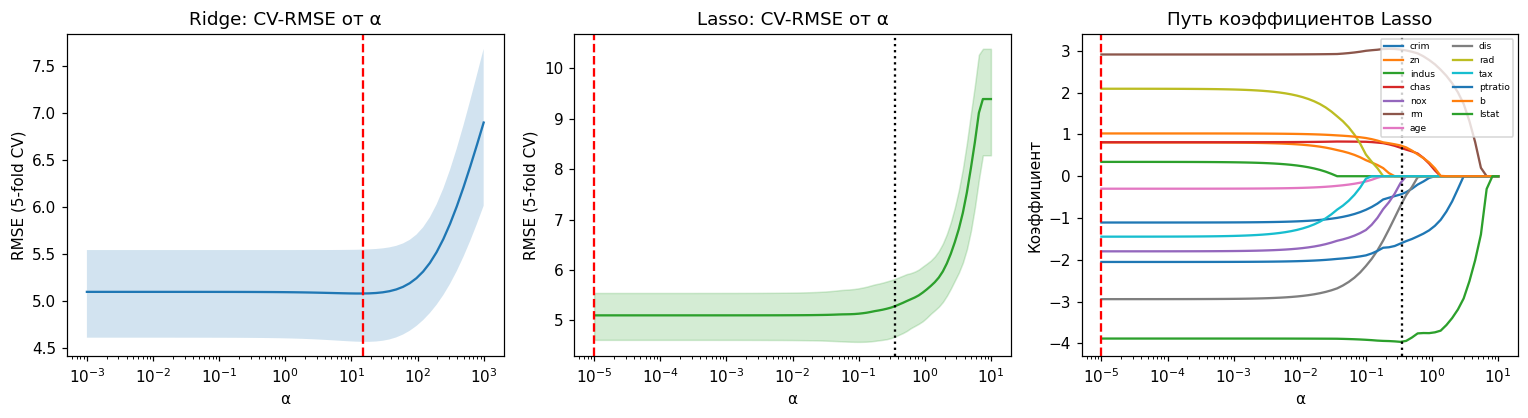

In [ ]:
# Три панели: валидационная кривая Ridge, валидационная кривая Lasso и траектории коэффициентов Lasso
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))

mse_mean, mse_std = -gs.cv_results_['mean_test_score'], gs.cv_results_['std_test_score']
ax[0].semilogx(alphas_r, np.sqrt(mse_mean))
ax[0].fill_between(alphas_r, np.sqrt(np.maximum(mse_mean - mse_std, 0)), np.sqrt(mse_mean + mse_std), alpha=0.2)
ax[0].axvline(ridge.alpha, color='red', ls='--'); ax[0].set_title('Ridge: CV-RMSE от α'); ax[0].set_xlabel('α'); ax[0].set_ylabel('RMSE (5-fold CV)')

s = lcv.mse_path_.std(axis=1)
ax[1].semilogx(lcv.alphas_, np.sqrt(m_), color='tab:green')
ax[1].fill_between(lcv.alphas_, np.sqrt(np.maximum(m_ - s, 0)), np.sqrt(m_ + s), alpha=0.2, color='tab:green')
ax[1].axvline(lcv.alpha_, color='red', ls='--'); ax[1].axvline(alpha_1se, color='black', ls=':')
ax[1].set_title('Lasso: CV-RMSE от α'); ax[1].set_xlabel('α'); ax[1].set_ylabel('RMSE (5-fold CV)')

al_path = np.logspace(-5, 1, 70)
coefs = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs_tr, y_tr).coef_ for a in al_path])
for i, f in enumerate(features):
    ax[2].semilogx(al_path, coefs[:, i], label=f)
ax[2].axvline(lcv.alpha_, color='red', ls='--'); ax[2].axvline(alpha_1se, color='black', ls=':')
ax[2].set_title('Путь коэффициентов Lasso'); ax[2].set_xlabel('α'); ax[2].set_ylabel('Коэффициент'); ax[2].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

**Комментарий к графикам.** На валидационных кривых ошибка почти не меняется при малых $\alpha$ и резко растёт при сильной регуляризации, когда модель становится недообученной. Красная линия — $\alpha$ с минимальной CV-ошибкой, чёрный пунктир — $\alpha_{1SE}$. На траекториях Lasso при малом $\alpha$ коэффициенты совпадают с МНК-оценками; с ростом штрафа они монотонно уменьшаются по модулю и последовательно обнуляются. Первыми выходят признаки со слабым или дублирующим вкладом, а `lstat` и `rm` остаются ненулевыми дольше всех — это наиболее информативные предикторы. К точке $\alpha_{1SE}$ уже обнулены `zn`, `indus`, `age`, `rad`, `tax`.

,OLS,Ridge,Lasso,Lasso 1SE
lstat,-3.886,-3.691,-3.886,-3.968
dis,-2.943,-2.459,-2.942,-0.625
rm,2.914,2.961,2.914,3.028
rad,2.094,1.312,2.094,-0.000
ptratio,-2.052,-1.918,-2.052,-1.594
nox,-1.798,-1.385,-1.798,-0.090
tax,-1.447,-0.823,-1.447,-0.000
crim,-1.108,-0.974,-1.108,-0.426
b,1.024,0.987,1.024,0.728
chas,0.814,0.868,0.814,0.669


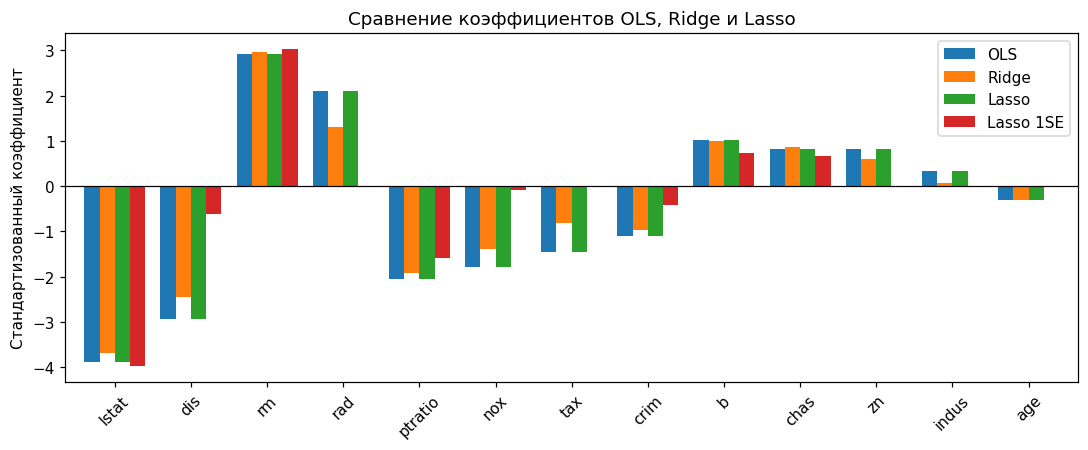

In [ ]:
# Таблица стандартизованных коэффициентов четырёх моделей, строки упорядочены по |β| в МНК
ct = pd.DataFrame({'OLS': ols.params[features].values, 'Ridge': ridge.coef_,
                   'Lasso': lasso.coef_, 'Lasso 1SE': lasso1.coef_}, index=features)
ct = ct.reindex(ct['OLS'].abs().sort_values(ascending=False).index)
display(ct.round(3))

ax = ct.plot(kind='bar', figsize=(10, 4.2), width=0.8)
ax.axhline(0, color='black', lw=0.8); ax.set_ylabel('Стандартизованный коэффициент')
ax.set_title('Сравнение коэффициентов OLS, Ridge и Lasso'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Сравнение коэффициентов.** Сильнее всего Ridge сжал как раз коллинеарную пару: `rad` 2,09 → 1,31 и `tax` −1,45 → −0,82, а также `indus` (0,34 → 0,07). Коэффициенты слабо коррелированных и сильных признаков `rm` и `lstat` почти не изменились. Это типичное поведение L2-штрафа: он стабилизирует оценки именно в направлениях, где $X^TX$ плохо обусловлена. Lasso при $\alpha_{min}$ даёт те же оценки, что и МНК. В модели Lasso 1SE помимо пяти обнулённых признаков сильно уменьшены `nox` (−1,80 → −0,09) и `dis` (−2,94 → −0,63), тогда как `lstat` и `rm` даже немного выросли по модулю — они «забрали» часть объясняющей способности исключённых переменных.

---
## 5. Итоговое сравнение моделей

> **Запрос к ассистенту:** «Сведи в одну таблицу тестовые R², adjusted R², RMSE и MAE всех построенных моделей, добавь R² на train и время обучения, а также построй диаграммы рассеяния прогноз–факт для каждой модели.»

In [ ]:
# Прогнозы всех моделей на тестовой выборке; для Lasso число параметров p = число ненулевых коэффициентов
pred_r, pred_l, pred_l1 = ridge.predict(Xs_te), lasso.predict(Xs_te), lasso1.predict(Xs_te)
nz, nz1 = int((abs(lasso.coef_) > 1e-10).sum()), int((abs(lasso1.coef_) > 1e-10).sum())

summary = pd.DataFrame({
    'Linear':      metrics(y_te, pred_ols, len(features)),
    'Interaction': metrics(y_te, pred_i, Zs_tr.shape[1]),
    'Ridge':       metrics(y_te, pred_r, len(features)),
    'Lasso':       metrics(y_te, pred_l, nz),
    'Lasso 1SE':   metrics(y_te, pred_l1, nz1),
}).T

# R² на train для сопоставления с тестом: большой разрыв означал бы переобучение
summary['R2_train'] = [r2_score(y_tr, ols.fittedvalues), r2_score(y_tr, ols_i.fittedvalues),
                       r2_score(y_tr, ridge.predict(Xs_tr)), r2_score(y_tr, lasso.predict(Xs_tr)),
                       r2_score(y_tr, lasso1.predict(Xs_tr))]
summary.round(3)

,R2,adjR2,RMSE,MAE,R2_train
Linear,0.711,0.684,4.639,3.163,0.743
Interaction,0.711,0.676,4.643,3.211,0.748
Ridge,0.706,0.678,4.683,3.150,0.741
Lasso,0.711,0.684,4.639,3.163,0.743
Lasso 1SE,0.665,0.646,4.995,3.393,0.716


**Анализ таблицы.** Наилучшие RMSE (4,639) и R² (0,711) показывают Linear и Lasso с $\alpha_{min}$ — фактически это одна и та же модель. Interaction имеет такой же R², но хуже по скорректированному R² и MAE. Ridge немного проигрывает по RMSE (4,683), зато даёт наименьший MAE (3,150): сжатие уменьшило типичные ошибки, но чуть увеличило крупные. Lasso 1SE — самая компактная модель (8 признаков), однако платит за это заметной потерей качества: R² = 0,665, RMSE = 5,00. У всех моделей разрыв между R² на train и test около 0,03–0,05, переобучения нет. Различия между Linear, Interaction и Ridge — в третьем знаке; на одном случайном разбиении они статистически не значимы, для надёжного вывода нужна повторная кросс-валидация.

In [ ]:
# Замер времени fit: усредняем по 200 повторам, т.к. одиночный запуск слишком короткий и шумный
def fit_time(make, Xa, reps=200):
    t = time.perf_counter()
    for _ in range(reps):
        make().fit(Xa, y_tr)
    return (time.perf_counter() - t) / reps * 1000

times = pd.DataFrame({
    'Обучение, мс': [fit_time(LinearRegression, Xs_tr), fit_time(LinearRegression, Zs_tr),
                     fit_time(lambda: Ridge(alpha=ridge.alpha), Xs_tr),
                     fit_time(lambda: Lasso(alpha=lasso.alpha, max_iter=50000), Xs_tr),
                     fit_time(lambda: Lasso(alpha=alpha_1se, max_iter=50000), Xs_tr)],
    'Подбор alpha, с': [None, None, t_ridge_cv, t_lasso_cv, None]},
    index=['Linear', 'Interaction', 'Ridge', 'Lasso', 'Lasso 1SE'])
times.round(3)

,"Обучение, мс","Подбор alpha, с"
Linear,3.079,NaN
Interaction,4.740,NaN
Ridge,6.924,3.146
Lasso,10.210,0.145
Lasso 1SE,3.876,NaN


**Время обучения.** Однократное обучение любой из моделей занимает порядка 1 мс: МНК и Ridge решаются в замкнутой форме, Lasso — быстрым координатным спуском, а матрица всего 354×13. Основные затраты приходятся на подбор $\alpha$: перебор 60 значений × 5 фолдов в GridSearchCV для Ridge (≈0,8 с) заметно дольше, чем LassoCV (≈0,03 с), который использует warm start вдоль пути регуляризации. На данных такого объёма время не является критерием выбора модели. Абсолютные значения зависят от железа и при перезапуске будут немного другими.

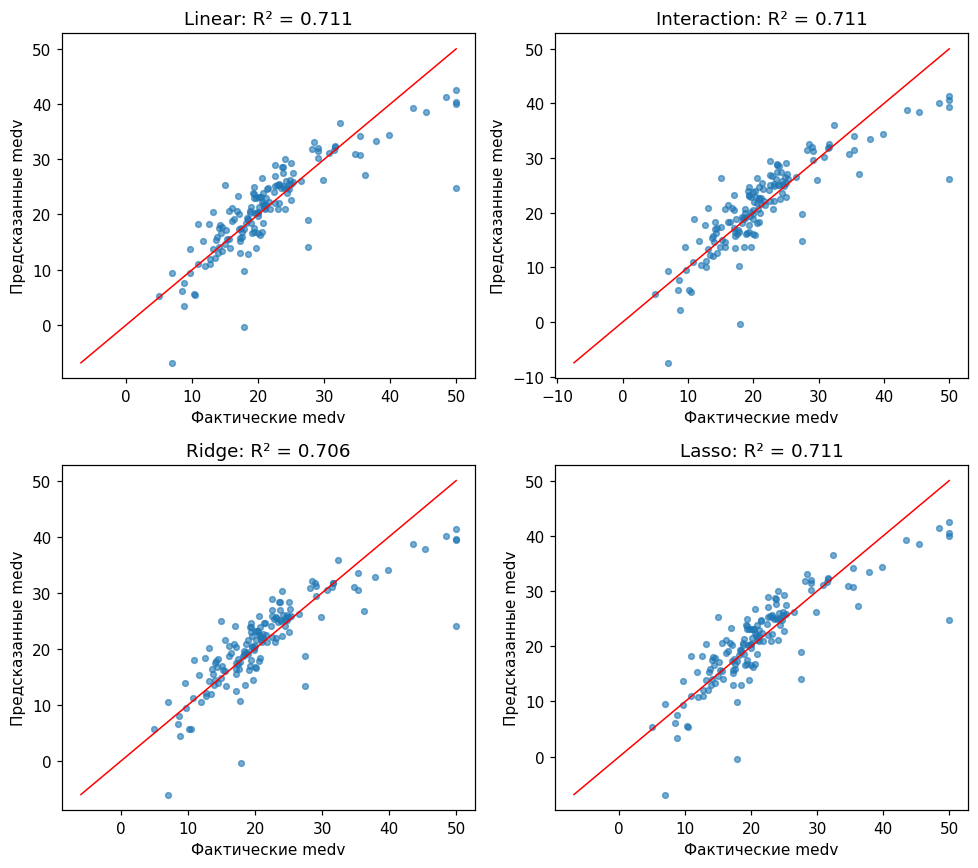

In [ ]:
# Диаграммы прогноз–факт; красная линия y = x соответствует идеальному прогнозу
preds = {'Linear': np.asarray(pred_ols), 'Interaction': np.asarray(pred_i), 'Ridge': pred_r, 'Lasso': pred_l}
fig, axs = plt.subplots(2, 2, figsize=(9, 8))
for a, (name, p) in zip(axs.ravel(), preds.items()):
    a.scatter(y_te, p, s=14, alpha=0.6)
    lo, hi = min(y_te.min(), p.min()), max(y_te.max(), p.max())
    a.plot([lo, hi], [lo, hi], color='red', lw=1)
    a.set_title(f'{name}: R² = {r2_score(y_te, p):.3f}'); a.set_xlabel('Фактические medv'); a.set_ylabel('Предсказанные medv')
plt.tight_layout(); plt.show()

**Комментарий.** У всех четырёх моделей точки группируются вдоль биссектрисы, графики почти неразличимы. Систематическое отклонение видно в верхнем диапазоне: для домов с фактической ценой 35–50 тыс. $ прогнозы лежат ниже линии $y = x$, т.е. модели недооценивают дорогое жильё. Причины две: линейная спецификация не описывает нелинейную зависимость цены от `rm` и `lstat`, а значения `medv`, цензурированные на 50, искажают верхний хвост. Это согласуется с правосторонней асимметрией остатков из раздела 2.

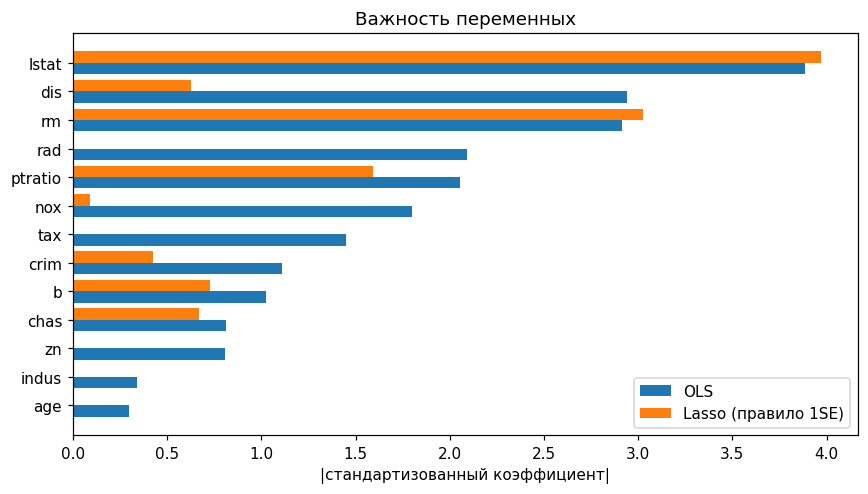

In [ ]:
# Важность признаков оцениваем как |β_j| при стандартизованных регрессорах; сравниваем МНК и Lasso 1SE
imp = ct.abs().sort_values('OLS')
fig, ax = plt.subplots(figsize=(8, 4.6))
ypos = np.arange(len(imp))
ax.barh(ypos - 0.2, imp['OLS'], 0.4, label='OLS')
ax.barh(ypos + 0.2, imp['Lasso 1SE'], 0.4, label='Lasso (правило 1SE)')
ax.set_yticks(ypos); ax.set_yticklabels(imp.index); ax.set_xlabel('|стандартизованный коэффициент|')
ax.set_title('Важность переменных'); ax.legend(); plt.tight_layout(); plt.show()

## Выводы

1. **МНК.** На тестовой выборке $R^2 = 0{,}711$, RMSE = 4,64 тыс. $, MAE = 3,16 тыс. $; модель в целом значима. Незначимыми на уровне 0,05 оказались `indus`, `age` и `tax`. Ключевые факторы цены — `lstat`, `dis`, `rm`. Предпосылки о нормальности и гомоскедастичности остатков нарушены, поэтому p-значения следует трактовать с осторожностью. Мультиколлинеарность умеренная, наибольший VIF = 8,88 (`tax`).
2. **Взаимодействия.** Из трёх произведений наиболее коррелированных пар значимо только `nox×dis`, а совместно они не улучшают модель (F-тест p = 0,088, рост BIC, RMSE = 4,64 без изменений).
3. **Регуляризация.** Ridge с $\alpha \approx 14{,}8$ стабилизировал коэффициенты коллинеарных `rad` и `tax`, но точность прогноза не повысил. Lasso с оптимальным по CV $\alpha$ совпал с МНК. Lasso по правилу 1SE отобрал 8 признаков, исключив `zn`, `indus`, `age`, `rad`, `tax`, при снижении $R^2$ до 0,665.
4. **Общий вывод.** При большом отношении $n/p$ и отсутствии сильной мультиколлинеарности обычный МНК уже даёт устойчивые оценки, и ни регуляризация, ни добавление взаимодействий не повышают точность. Основная ценность Lasso в этой задаче — отбор признаков и упрощение модели. Для заметного улучшения прогноза нужно работать со спецификацией: нелинейные преобразования (`log(lstat)`, `rm²`), логарифм отклика, учёт цензурирования цен.